In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn

In [22]:
df = pd.read_csv('../data/subsea.csv')

In [23]:
df.head()

,time,MIV_17_1402_State [],PT_17_1002 [bara],TZT_17_1002 [°C]
0,2026-02-13T06:12:52.673Z,NaN,63.631588,NaN
1,2026-02-13T06:12:53.767Z,NaN,63.591072,NaN
2,2026-02-13T06:14:12.523Z,0.0,NaN,NaN
3,2026-02-13T06:19:35.169Z,NaN,NaN,50.121681
4,2026-02-13T06:19:36.262Z,NaN,NaN,50.120045


In [24]:
rename_map = {
    "MIV_17_1402_State []": "state",
    "PT_17_1002 [bara]": "Pump outlet pressure (Mean)",
    "TZT_17_1002 [°C]": "temp",
}

df = df.rename(columns=rename_map)

In [25]:
df['time'] = pd.to_datetime(
    df['time'],
    format='mixed',
    utc=True
)

df = df.sort_values('time').reset_index(drop=True)

df['elapsed_seconds'] = (
    df['time'] - df['time'].iloc[0]
).dt.total_seconds()

df['reading_interval_s'] = (
    df['time'].diff().dt.total_seconds()
)

In [26]:
df['reading_interval_s'].describe()

count    11038.000000
mean       102.121710
std        195.915366
min          0.000000
25%          1.094000
50%          4.375000
75%        139.687250
max       9900.496000
Name: reading_interval_s, dtype: float64

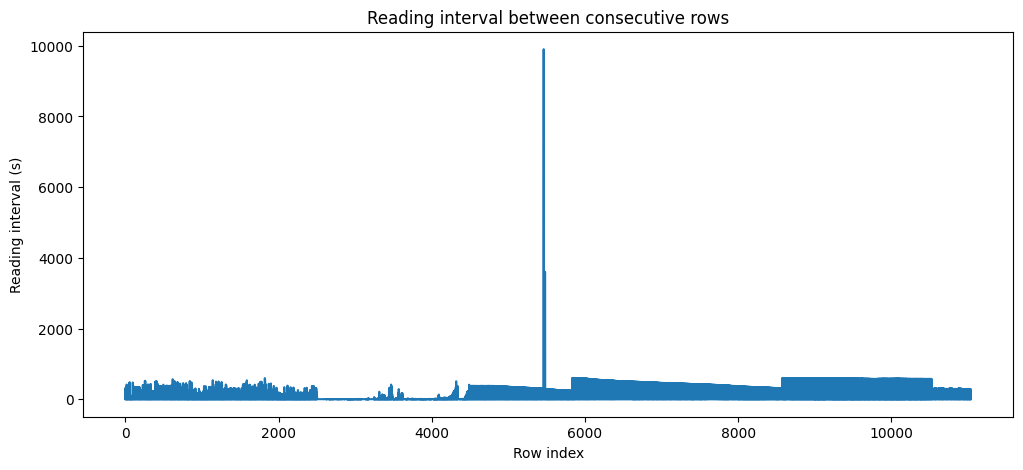

In [28]:

plt.figure(figsize=(12, 5))
plt.plot(df.index, df['reading_interval_s'])
plt.xlabel('Row index')
plt.ylabel('Reading interval (s)')
plt.title('Reading interval between consecutive rows')
plt.show()

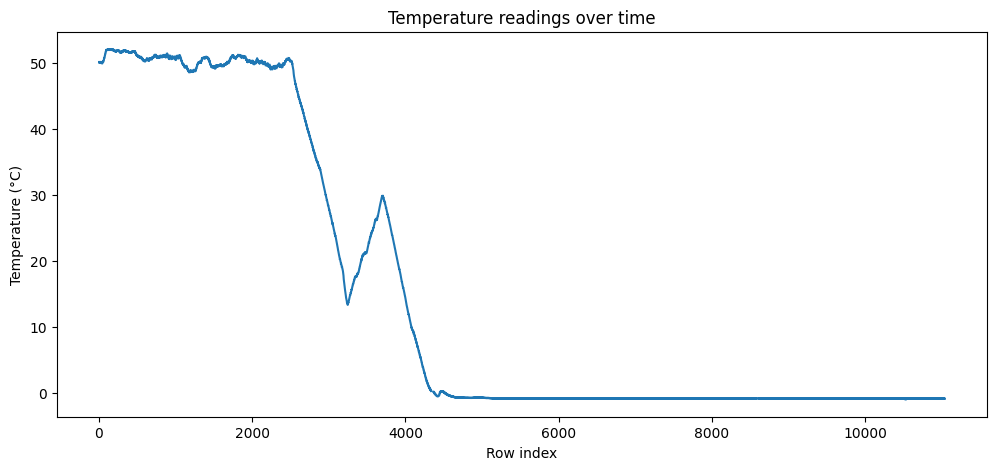

In [29]:
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['temp'])
plt.xlabel('Row index')
plt.ylabel('Temperature (°C)')
plt.title('Temperature readings over time')
plt.show()

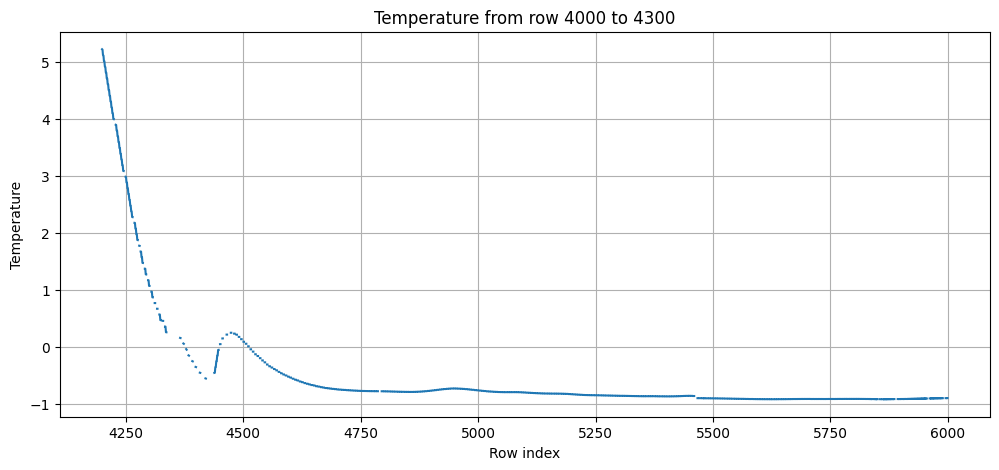

In [41]:
temp_section = df.iloc[4200:6001]

plt.figure(figsize=(12, 5))
plt.plot(temp_section.index, temp_section['temp'])

plt.xlabel('Row index')
plt.ylabel('Temperature')
plt.title('Temperature from row 4000 to 4300')
plt.grid(True)
plt.show()

In [49]:
start_idx = 4800
df_test = df.iloc[start_idx:].copy()

In [54]:
df_test['reading_interval_s'].describe()

count    6239.000000
mean      136.842539
std       238.777921
min         0.000000
25%         1.094000
50%         6.562000
75%       232.966000
max      9900.496000
Name: reading_interval_s, dtype: float64

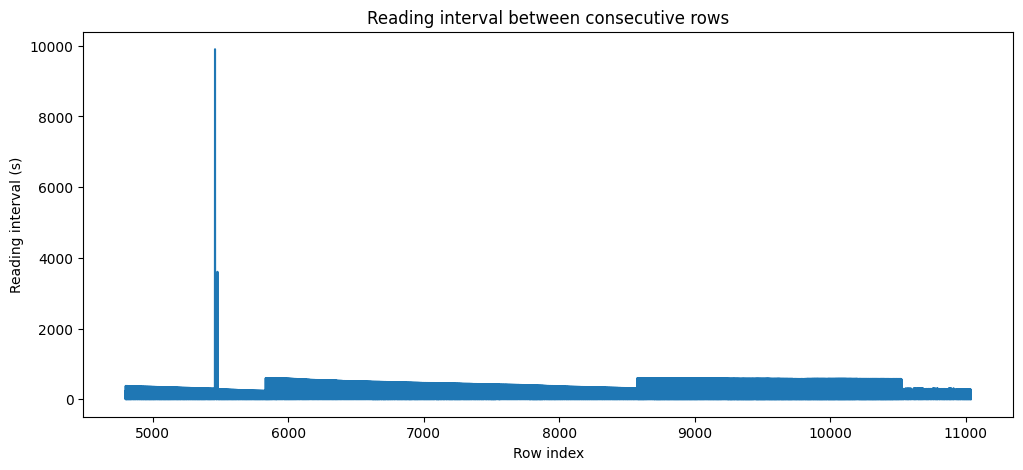

In [55]:
plt.figure(figsize=(12, 5))
plt.plot(df_test.index, df_test['reading_interval_s'])
plt.xlabel('Row index')
plt.ylabel('Reading interval (s)')
plt.title('Reading interval between consecutive rows')
plt.show()

## 1 hz interpolation

In [61]:
df_1s = (
    df_test
    .set_index('time')
    .resample('1s')
    .mean(numeric_only=True)
    .interpolate(method='time')
)

In [62]:
df_1s['elapsed_seconds'] = (
    df_1s.index - df_1s.index[0]
).total_seconds()

In [63]:
df_1s.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 853541 entries, 2026-02-16 10:14:12+00:00 to 2026-02-26 07:19:52+00:00
Freq: s
Data columns (total 5 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   state                        853163 non-null  float64
 1   Pump outlet pressure (Mean)  853163 non-null  float64
 2   temp                         853541 non-null  float64
 3   elapsed_seconds              853541 non-null  float64
 4   reading_interval_s           853541 non-null  float64
dtypes: float64(5)
memory usage: 39.1 MB


In [72]:
nan_idx = df_1s.index[
    df_1s['Pump outlet pressure (Mean)'].isna()
]

print(nan_idx.tolist())

[Timestamp('2026-02-16 10:14:12+0000', tz='UTC'), Timestamp('2026-02-16 10:14:13+0000', tz='UTC'), Timestamp('2026-02-16 10:14:14+0000', tz='UTC'), Timestamp('2026-02-16 10:14:15+0000', tz='UTC'), Timestamp('2026-02-16 10:14:16+0000', tz='UTC'), Timestamp('2026-02-16 10:14:17+0000', tz='UTC'), Timestamp('2026-02-16 10:14:18+0000', tz='UTC'), Timestamp('2026-02-16 10:14:19+0000', tz='UTC'), Timestamp('2026-02-16 10:14:20+0000', tz='UTC'), Timestamp('2026-02-16 10:14:21+0000', tz='UTC'), Timestamp('2026-02-16 10:14:22+0000', tz='UTC'), Timestamp('2026-02-16 10:14:23+0000', tz='UTC'), Timestamp('2026-02-16 10:14:24+0000', tz='UTC'), Timestamp('2026-02-16 10:14:25+0000', tz='UTC'), Timestamp('2026-02-16 10:14:26+0000', tz='UTC'), Timestamp('2026-02-16 10:14:27+0000', tz='UTC'), Timestamp('2026-02-16 10:14:28+0000', tz='UTC'), Timestamp('2026-02-16 10:14:29+0000', tz='UTC'), Timestamp('2026-02-16 10:14:30+0000', tz='UTC'), Timestamp('2026-02-16 10:14:31+0000', tz='UTC'), Timestamp('2026-02-

In [73]:
pressure_nan = df_1s['Pump outlet pressure (Mean)'].isna()

print("Number of NaNs:", pressure_nan.sum())
print("First valid pressure row:", df_1s['Pump outlet pressure (Mean)'].first_valid_index())
print("Last valid pressure row:", df_1s['Pump outlet pressure (Mean)'].last_valid_index())

Number of NaNs: 378
First valid pressure row: 2026-02-16 10:20:30+00:00
Last valid pressure row: 2026-02-26 07:19:52+00:00


In [74]:
pressure_col = 'Pump outlet pressure (Mean)'

first_valid = df_1s[pressure_col].first_valid_index()

print("First valid:", first_valid)
print(
    "NaNs after first valid:",
    df_1s.loc[first_valid:, pressure_col].isna().sum()
)

First valid: 2026-02-16 10:20:30+00:00
NaNs after first valid: 0


In [75]:
df_1s = df_1s.loc[first_valid:].copy()

In [76]:
df_1s['elapsed_seconds'] = (
    df_1s.index - df_1s.index[0]
).total_seconds()

In [77]:
df_1s.head()

,state,Pump outlet pressure (Mean),temp,elapsed_seconds,reading_interval_s
time,,,,,
2026-02-16 10:20:30+00:00,0.0,36.697800,-0.776679,0.0,188.669000
2026-02-16 10:20:31+00:00,0.0,36.697033,-0.776680,1.0,1.095000
2026-02-16 10:20:32+00:00,0.0,36.697032,-0.776682,2.0,2.089751
2026-02-16 10:20:33+00:00,0.0,36.697031,-0.776683,3.0,3.084502
2026-02-16 10:20:34+00:00,0.0,36.697030,-0.776685,4.0,4.079253


In [78]:
df_1s['TS outlet pressure (Mean)'] = 0.0
df_1s['TS inlet pressure (Mean)'] = 0.0

In [79]:
tmp = df_1s.copy()

In [80]:
tmp['Differential pressure (Mean)'] = tmp['TS inlet pressure (Mean)'] - tmp['TS outlet pressure (Mean)']
tmp['Pump to inlet DP'] = tmp['Pump outlet pressure (Mean)'] - tmp['TS inlet pressure (Mean)']
tmp['Total system DP'] = tmp['Pump outlet pressure (Mean)'] - tmp['TS outlet pressure (Mean)']

In [81]:
baseline = tmp.iloc[:60]

tmp['rel_tot_dp_change'] = tmp['Total system DP'] / baseline['Total system DP'].median()
tmp['rel_ts_dp_change'] = tmp['Differential pressure (Mean)'] / baseline['Differential pressure (Mean)'].median()
tmp['rel_p_ts_dp_change'] = tmp['Pump to inlet DP'] / baseline['Pump to inlet DP'].median()

In [82]:
tmp['Pressure_Ratio'] = (tmp['TS inlet pressure (Mean)'] - tmp['TS outlet pressure (Mean)']) / \
                           (tmp['Pump outlet pressure (Mean)'] - tmp['TS inlet pressure (Mean)'] + 1e-6)

base_ratio_val = tmp['Pressure_Ratio'].iloc[:60].median()
    
tmp['Relative_Ratio_Dev'] = (tmp['Pressure_Ratio'] / (base_ratio_val + 1e-6) - 1).abs()

In [85]:
scaler = joblib.load('../models/anomaly_scaler.joblib')
iso_model = joblib.load('../models/anomaly_isolation_forest.joblib')

In [86]:
feature_cols = [
'rel_tot_dp_change', 'rel_ts_dp_change', 'rel_p_ts_dp_change','Relative_Ratio_Dev']

X_scaled = scaler.transform(tmp[feature_cols])
tmp['anomaly_score'] = iso_model.decision_function(X_scaled)

In [88]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

feature_cols = [
    'rel_tot_dp_change', 
    'rel_ts_dp_change', 
    'rel_p_ts_dp_change',
    'Relative_Ratio_Dev',
    'anomaly_score'
]

class HydraulicLSTM(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, num_layers=2, num_classes=4):
        super(HydraulicLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)
        
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :]) 
        return out

model = HydraulicLSTM(input_size=len(feature_cols), hidden_size=64, num_layers=2, num_classes=4)
model.load_state_dict(torch.load('../models/best_hydraulic_lstm.pth', map_location=device))
lstm_scaler = joblib.load('../models/lstm_scaler.joblib')
model.to(device)
model.eval() 

predicted_states = [0] * 59 

with torch.no_grad(): 
    for current_sec in range(59, len(tmp)):
        window_raw = tmp[feature_cols].iloc[current_sec - 59 : current_sec + 1].values
        window_scaled = lstm_scaler.transform(window_raw)
        window_tensor = torch.tensor(window_scaled, dtype=torch.float32).unsqueeze(0).to(device)
        outputs = model(window_tensor)
        _, predicted_class = torch.max(outputs, 1)
        
        predicted_states.append(predicted_class.item())
tmp = tmp.copy()
tmp['predicted_state'] = predicted_states


Using device: cpu


In [100]:
tmp[['predicted_state']].value_counts()

predicted_state
0                  853163
Name: count, dtype: int64

In [92]:
def plot_rdd(df):
    fig, ax = plt.subplots(figsize=(16, 6))

    x_axis = df['elapsed_seconds']

    ax.plot(x_axis, df['Relative_Ratio_Dev'], color='skyblue', alpha=0.4, label='Raw Deviation')

    smoothed = df['Relative_Ratio_Dev'].rolling(window=100, min_periods=1).mean()
    ax.plot(x_axis, smoothed, color='darkblue', linewidth=2, label='Smoothed Trend')

    ax.set_title(' - Relative Ratio Deviation Over Time')
    ax.set_ylabel('Deviation Magnitude')
    ax.set_xlabel('Time (elapsed seconds)')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()

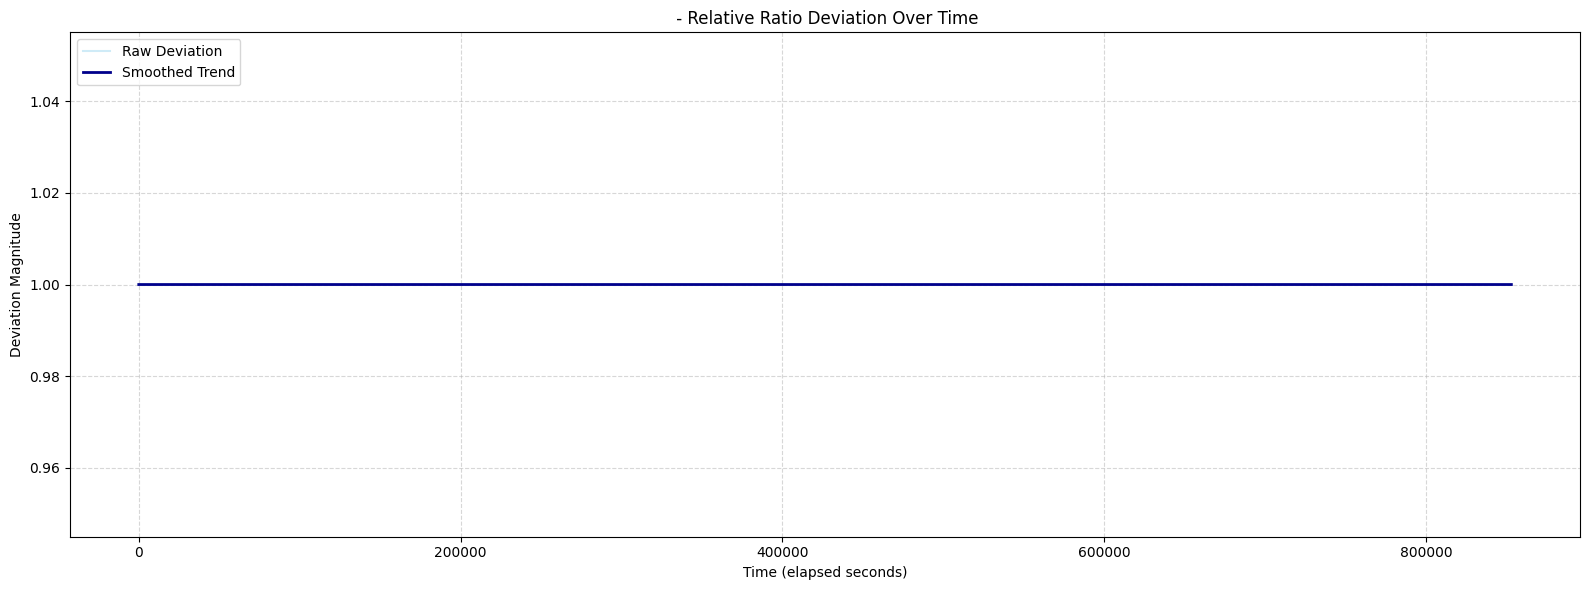

In [93]:
plot_rdd(tmp)

In [114]:
def plot_anomaly(df):
    fig, ax = plt.subplots(figsize=(16, 6))

    x_axis = df['elapsed_seconds']

    ax.plot(x_axis, df['anomaly_score'], color='skyblue', alpha=0.4, label='anomaly score')

    smoothed = df['anomaly_score'].rolling(window=100, min_periods=1).mean()
    ax.plot(x_axis, smoothed, color='darkblue', linewidth=2, label='Smoothed Trend')

    ax.set_title(' - Anomaly Score Over Time')
    ax.set_ylabel('Anomaly Magnitude')
    ax.set_xlabel('Time (elapsed seconds)')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

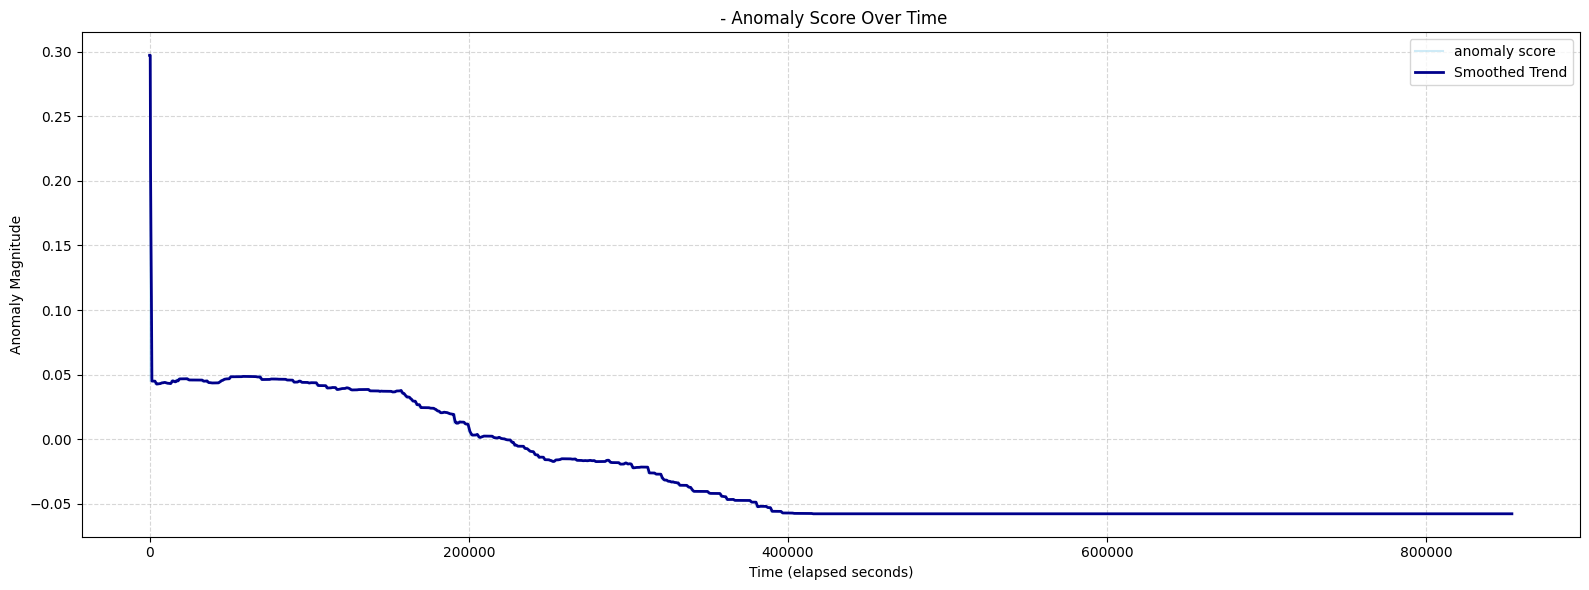

In [115]:
plot_anomaly(tmp)

In [97]:
def plot(df):
    fig, ax = plt.subplots(figsize=(16, 6))

    x_axis = df['elapsed_seconds']

    ax.plot(x_axis, df['Pump outlet pressure (Mean)'], color='skyblue', alpha=0.4, label='anomaly score')

    smoothed = df['Pump outlet pressure (Mean)'].rolling(window=100, min_periods=1).mean()
    ax.plot(x_axis, smoothed, color='darkblue', linewidth=2, label='Smoothed Trend')

    ax.set_title(' - Anomaly Score Over Time')
    ax.set_ylabel('Anomaly Magnitude')
    ax.set_xlabel('Time (elapsed seconds)')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()

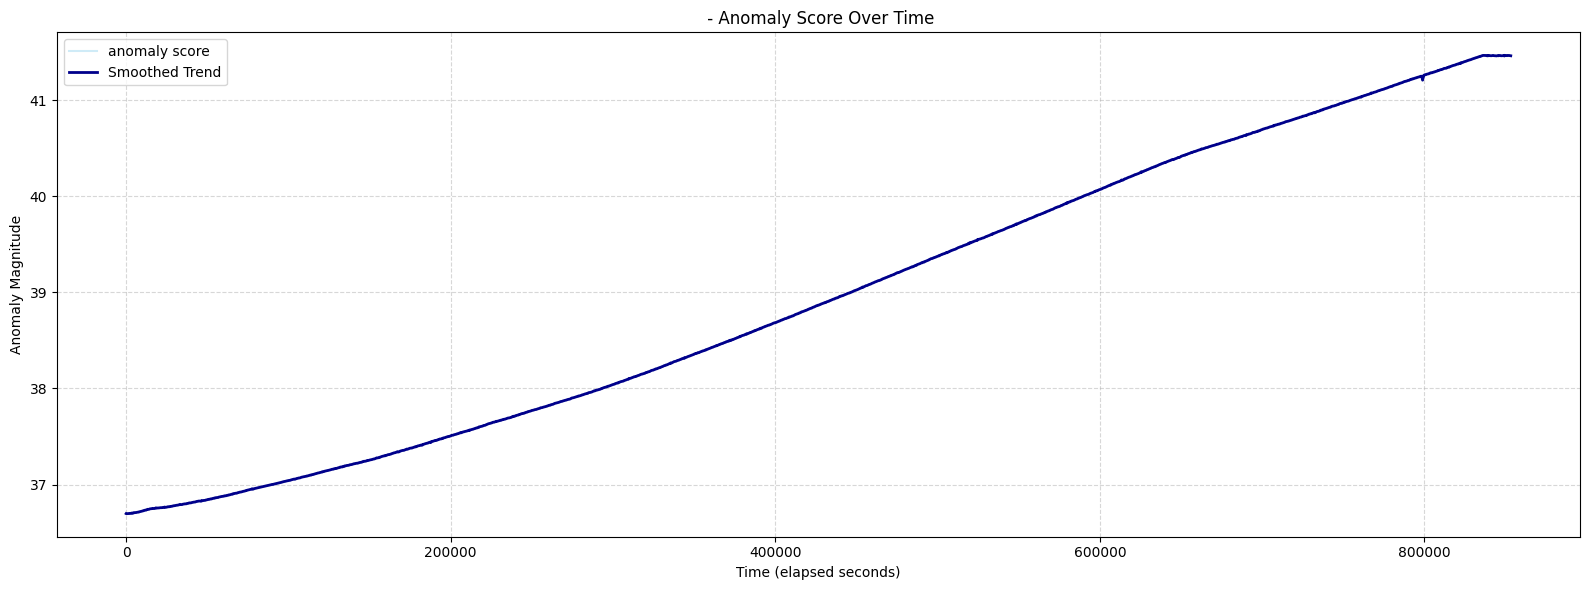

In [98]:
plot(tmp)

## 10 hz interpolation

In [102]:
df_10s = (
    df_test
    .set_index('time')
    .resample('10s')
    .mean(numeric_only=True)
    .interpolate(method='time')
)

In [103]:
df_10s['elapsed_seconds'] = (
    df_10s.index - df_10s.index[0]
).total_seconds()

In [104]:
df_10s['TS outlet pressure (Mean)'] = 0.0
df_10s['TS inlet pressure (Mean)'] = 0.0

In [106]:
tmp = df_10s.copy()

In [107]:
tmp['Differential pressure (Mean)'] = tmp['TS inlet pressure (Mean)'] - tmp['TS outlet pressure (Mean)']
tmp['Pump to inlet DP'] = tmp['Pump outlet pressure (Mean)'] - tmp['TS inlet pressure (Mean)']
tmp['Total system DP'] = tmp['Pump outlet pressure (Mean)'] - tmp['TS outlet pressure (Mean)']

In [108]:
baseline = tmp.iloc[:60]

tmp['rel_tot_dp_change'] = tmp['Total system DP'] / baseline['Total system DP'].median()
tmp['rel_ts_dp_change'] = tmp['Differential pressure (Mean)'] / baseline['Differential pressure (Mean)'].median()
tmp['rel_p_ts_dp_change'] = tmp['Pump to inlet DP'] / baseline['Pump to inlet DP'].median()

In [109]:
tmp['Pressure_Ratio'] = (tmp['TS inlet pressure (Mean)'] - tmp['TS outlet pressure (Mean)']) / \
                           (tmp['Pump outlet pressure (Mean)'] - tmp['TS inlet pressure (Mean)'] + 1e-6)

base_ratio_val = tmp['Pressure_Ratio'].iloc[:60].median()
    
tmp['Relative_Ratio_Dev'] = (tmp['Pressure_Ratio'] / (base_ratio_val + 1e-6) - 1).abs()

In [110]:
scaler = joblib.load('../models/anomaly_scaler.joblib')
iso_model = joblib.load('../models/anomaly_isolation_forest.joblib')

In [111]:
feature_cols = [
'rel_tot_dp_change', 'rel_ts_dp_change', 'rel_p_ts_dp_change','Relative_Ratio_Dev']

X_scaled = scaler.transform(tmp[feature_cols])
tmp['anomaly_score'] = iso_model.decision_function(X_scaled)

In [112]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

feature_cols = [
    'rel_tot_dp_change', 
    'rel_ts_dp_change', 
    'rel_p_ts_dp_change',
    'Relative_Ratio_Dev',
    'anomaly_score'
]

class HydraulicLSTM(nn.Module):
    def __init__(self, input_size=5, hidden_size=64, num_layers=2, num_classes=4):
        super(HydraulicLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)
        
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        out, _ = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :]) 
        return out

model = HydraulicLSTM(input_size=len(feature_cols), hidden_size=64, num_layers=2, num_classes=4)
model.load_state_dict(torch.load('../models/best_hydraulic_lstm.pth', map_location=device))
lstm_scaler = joblib.load('../models/lstm_scaler.joblib')
model.to(device)
model.eval() 

predicted_states = [0] * 59 

with torch.no_grad(): 
    for current_sec in range(59, len(tmp)):
        window_raw = tmp[feature_cols].iloc[current_sec - 59 : current_sec + 1].values
        window_scaled = lstm_scaler.transform(window_raw)
        window_tensor = torch.tensor(window_scaled, dtype=torch.float32).unsqueeze(0).to(device)
        outputs = model(window_tensor)
        _, predicted_class = torch.max(outputs, 1)
        
        predicted_states.append(predicted_class.item())
tmp = tmp.copy()
tmp['predicted_state'] = predicted_states


Using device: cpu


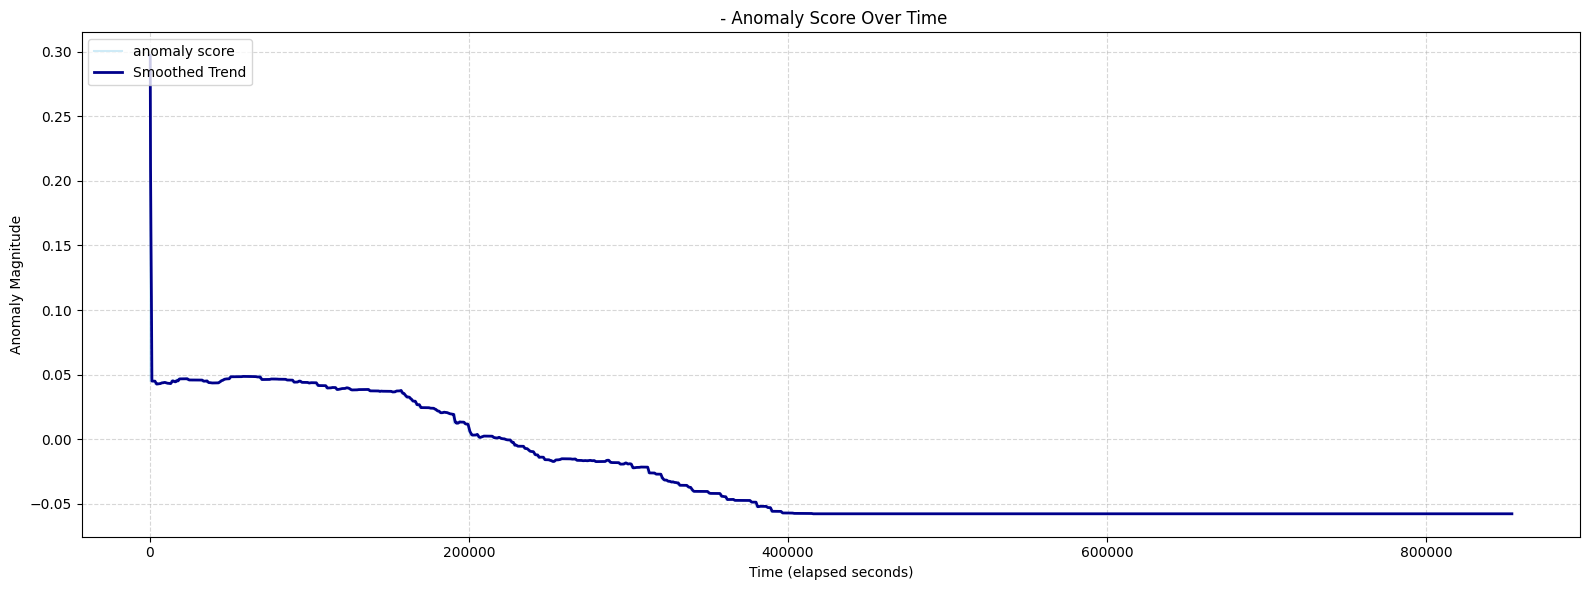

In [113]:
plot_anomaly(tmp)